# 1.2. Prepare semantic segmentation data

Goal: prepare MRI slices and their original expert masks for
pixel-level classification: background, edema, non-enhancing
tumor, and enhancing tumor.


This notebook initially inspects one case and one slice.
Training evaluation will require separate patient groups.

# 0. Configure reproducible random states

In [38]:
import os

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import random
import numpy as np
import torch

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


# Outside the function: no indentation.
seed_everything(SEED)

print("Seed setup completed:", SEED)

Seed setup completed: 42


# 1. Select an example brain MRI case

Select the downloaded example MRI case 457.


Extract the ZIP file of sample case 457 (located in the github repo directory `/content/data/msd_task01_brain_tumour/verified_sample`)

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile

# Pin to the commit containing the verified sample.
url = (
    "https://raw.githubusercontent.com/"
    "vuthanhvannguyen2006-commits/brain-mri-anomaly-lab/"
    "4cd6667/data/msd_brain_tumour_sample.zip"
)

zip_path = Path("/content/verified_msd_sample.zip")
DATA_DIR = Path("/content/data/msd_task01_brain_tumour/verified_sample")

urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None, "ZIP integrity check failed."
    archive.extractall(DATA_DIR)

image_path = DATA_DIR / "imagesTr" / "BRATS_457.nii.gz"
mask_path = DATA_DIR / "labelsTr" / "BRATS_457.nii.gz"

assert image_path.is_file(), "MRI file missing."
assert mask_path.is_file(), "Mask file missing."

print("Data folder:", DATA_DIR)
print("MRI:", image_path.name, f"({image_path.stat().st_size:,} bytes)")
print("Mask:", mask_path.name, f"({mask_path.stat().st_size:,} bytes)")

Data folder: /content/data/msd_task01_brain_tumour/verified_sample
MRI: BRATS_457.nii.gz (9,893,368 bytes)
Mask: BRATS_457.nii.gz (22,339 bytes)


In [2]:
%pip install -q nibabel

import json
import nibabel as nib
import numpy as np

metadata = json.loads((DATA_DIR / "dataset.json").read_text())

image = nib.as_closest_canonical(nib.load(image_path))
mask_image = nib.as_closest_canonical(nib.load(mask_path))

volume = image.get_fdata(dtype=np.float32)
mask_values = mask_image.get_fdata(dtype=np.float32)

print("MRI shape:", volume.shape)
print("Mask shape:", mask_values.shape)

MRI shape: (240, 240, 155, 4)
Mask shape: (240, 240, 155)


# 2. Check technical compatibility

## Mask Check

In [3]:
def status(passed):
    return "[APPROPRIATE]" if passed else "[NOT APPROPRIATE]"


sizes_match = volume.shape[:3] == mask_values.shape
print(
    f"Spatial sizes: MRI {volume.shape[:3]}, mask {mask_values.shape}; "
    f"match = {sizes_match} {status(sizes_match)}"
)

grids_match = np.allclose(image.affine, mask_image.affine)
print(f"Spatial grids: match = {grids_match} {status(grids_match)}")

finite = bool(np.isfinite(mask_values).all())
print(f"Mask values: all finite = {finite} {status(finite)}")

integers = finite and np.allclose(mask_values, np.round(mask_values))
print(f"Mask labels: integer-like = {integers} {status(integers)}")

unique_values = np.unique(mask_values)
labels_valid = integers and np.isin(
    np.round(unique_values), [0, 1, 2, 3]
).all()

print(f"Unique labels: {unique_values} {status(labels_valid)}")

# Convert only when all checks pass.
mask = None
ready = sizes_match and grids_match and finite and integers and labels_valid

if ready:
    mask = np.round(mask_values).astype(np.uint8)
    print(f"Mask conversion: dtype = {mask.dtype} {status(True)}")
else:
    print(f"Mask conversion: skipped {status(False)}")

Spatial sizes: MRI (240, 240, 155), mask (240, 240, 155); match = True [APPROPRIATE]
Spatial grids: match = True [APPROPRIATE]
Mask values: all finite = True [APPROPRIATE]
Mask labels: integer-like = True [APPROPRIATE]
Unique labels: [0. 1. 2. 3.] [APPROPRIATE]
Mask conversion: dtype = uint8 [APPROPRIATE]


| Check or operation | Purpose | Evaluation of my results |
|---|---|---|
| `volume.shape[:3] == mask_values.shape` | Confirms matching width, height, and depth. | MRI spatial and mask shape match: YES (appropriate)
| `np.allclose(image.affine, mask_image.affine)` | Confirms matching physical position, voxel spacing, and orientation. | Matching grids: YES (appropriate) |
| `np.isfinite(mask_values).all()` | Checks for invalid values such as `NaN` or infinity. | All values finite: YES (appropriate) |
| `np.allclose(mask_values, np.round(mask_values))` | Confirms mask labels (categories: edema, etc.) are effectively whole numbers. | All values effectively integers: YES (appropriate) |
| Expected labels are within `{0, 1, 2, 3}` | Detects unexpected annotation values. Check **before** converting to `uint8`. | Unique labels: [0, 1, 2, 3]; all expected: YES (appropriate) |
| `np.round(mask_values).astype(np.uint8)` | Stores validated labels compactly as integers. This is a conversion, not a check. | Resulting dtype: uint8 integers (appropriate) |

## MRI Intensity Check

In [4]:
image_finite = bool(np.isfinite(volume).all())
print(
    f"MRI intensities: all finite = {image_finite} "
    f"{status(image_finite)}"
)

MRI intensities: all finite = True [APPROPRIATE]


# 3. Select 1 slice from the example MRI sequence


Check available MRI sequences (modalities):

In [5]:
print("Available MRI sequences:")

for index, name in metadata["modality"].items():
    print(f"Sequence {index}: {name}")

Available MRI sequences:
Sequence 0: FLAIR
Sequence 1: T1w
Sequence 2: t1gd
Sequence 3: T2w


💭 Comment: We initially use FLAIR alone to simplify the learning exercise.
This is an input-design choice with medical implications:
FLAIR may not provide enough information to distinguish every
annotated category. We will later compare multi-sequence inputs.

The selected slice has the most annotated pixels for inspection;
this is not our training-sampling policy.

Select 1 slice: `channel = 0` selects FLAIR images only.

In [6]:
# FLAIR is sequence 0 in this dataset.
channel = 0
scan = volume[..., channel]

# Select the slice with the most annotated pixels (to easily view masks).
counts_per_slice = (mask > 0).sum(axis=(0, 1))
z = int(counts_per_slice.argmax())

# Apply the same orientation change to image and mask.
mri_slice = np.flipud(scan[:, :, z].T).copy()
mask_slice = np.flipud(mask[:, :, z].T).copy()

print("Sequence:", metadata["modality"][str(channel)])
print("Slice:", z)
print("MRI slice shape:", mri_slice.shape)
print("Mask slice shape:", mask_slice.shape)
print("Labels present:", np.unique(mask_slice))

Sequence: FLAIR
Slice: 52
MRI slice shape: (240, 240)
Mask slice shape: (240, 240)
Labels present: [0 1 3]


ℹ Important code components:
- `.sum(axis=(0, 1))` counts annotated pixels separately for each slice (to not wrongly aggregate across slices).
- `.argmax()` selects the slice with the largest count. This is for inspection (since it is easier to view a large mask), not a training-sampling rule.
- `.T` and `np.flipud()` orient the arrays for display. Applying both to the image and mask preserves alignment.

# 4. Optional exploration: Why we preserve native masks

This experiment demonstrates how outline conversion can change
expert annotations. It is not part of the semantic training pipeline.

In [7]:
%pip install -q opencv-python-headless

In [8]:
import cv2

region_boundaries = {}

for label in (1, 2, 3):
    # Binary image: 1 for this category, 0 everywhere else.
    binary_mask = (mask_slice == label).astype(np.uint8)

    contours, hierarchy = cv2.findContours(
        binary_mask,
        cv2.RETR_TREE,
        cv2.CHAIN_APPROX_NONE,
    )

    region_boundaries[label] = {
        "contours": contours,
        "hierarchy": hierarchy,
    }

    # Nesting depth distinguishes region edges from hole boundaries.
    depths = []

    if hierarchy is not None:
        for index in range(len(contours)):
            depth = 0
            parent = hierarchy[0, index, 3]

            while parent != -1:
                depth += 1
                parent = hierarchy[0, parent, 3]

            depths.append(depth)

    region_edges = sum(depth % 2 == 0 for depth in depths)
    hole_edges = sum(depth % 2 == 1 for depth in depths)

    print(
        f"{label}: {metadata['labels'][str(label)]} — "
        f"{region_edges} region boundaries, {hole_edges} hole boundaries"
    )

1: edema — 4 region boundaries, 7 hole boundaries
2: non-enhancing tumor — 0 region boundaries, 0 hole boundaries
3: enhancing tumour — 2 region boundaries, 0 hole boundaries


Inspect original boundaries in the human-annotated masks:

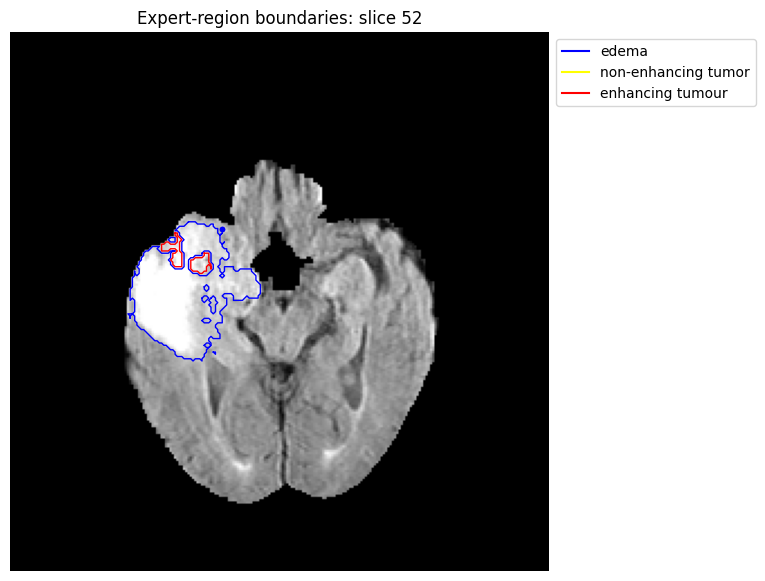

In [9]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

valid = scan[np.isfinite(scan) & (scan != 0)]
vmin, vmax = np.percentile(valid, [1, 99])

colors = {1: "blue", 2: "yellow", 3: "red"}

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    mri_slice,
    cmap="gray",
    origin="upper",
    vmin=vmin,
    vmax=vmax,
)

for label, result in region_boundaries.items():
    for contour in result["contours"]:
        points = contour.reshape(-1, 2)

        # Repeat the first point to close the displayed boundary.
        closed = np.vstack([points, points[:1]])

        ax.plot(
            closed[:, 0],
            closed[:, 1],
            color=colors[label],
            linewidth=1,
            marker="." if len(points) < 3 else None,
        )

legend = [
    Line2D(
        [0], [0],
        color=colors[label],
        label=metadata["labels"][str(label)],
    )
    for label in (1, 2, 3)
]

ax.legend(handles=legend, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"Expert-region boundaries: slice {z}")
ax.axis("off")
plt.show()

### Inspection notes

- Slice 52 contains edema and enhancing tumor; non-enhancing tumor is absent from this slice.
- Edema has 4 region boundaries and 7 hole boundaries.
- Enhancing tumor has 2 region boundaries and no holes.
- These counts describe 2D annotation geometry, not the number of tumors.
- Holes indicate areas excluded from that category; they are not necessarily healthy tissue.
- Filling holes could overwrite other labels and inflate region measurements.
- Preserve the original integer mask as the semantic training target. Contours are used here only for inspection.
- The displayed boundaries come from expert annotations, not model predictions.

Reconstruct mask fillings: Preserving original mask vs Filling in mask holes

In [10]:
import cv2
import numpy as np

reconstruction_results = {}

for label in (1, 2, 3):
    original = (mask_slice == label).astype(np.uint8)

    contours = region_boundaries[label]["contours"]
    hierarchy = region_boundaries[label]["hierarchy"]

    preserved = np.zeros_like(original)
    filled = np.zeros_like(original)

    if contours:
        # Draw all boundaries together, respecting nested holes.
        cv2.drawContours(
            preserved,
            contours,
            contourIdx=-1,
            color=1,
            thickness=cv2.FILLED,
            hierarchy=hierarchy,
        )

        # Comparison only: fill every foreground boundary independently.
        # This intentionally loses the hole exclusions.
        for index, contour in enumerate(contours):
            depth = 0
            parent = hierarchy[0, index, 3]

            while parent != -1:
                depth += 1
                parent = hierarchy[0, parent, 3]

            if depth % 2 == 0:
                cv2.drawContours(
                    filled,
                    [contour],
                    contourIdx=-1,
                    color=1,
                    thickness=cv2.FILLED,
                )

    preserved_errors = int(np.count_nonzero(preserved != original))
    added = (filled == 1) & (original == 0)
    removed = (filled == 0) & (original == 1)

    name = metadata["labels"][str(label)]

    print(f"\n{label}: {name}")
    print(
        f"Hole-preserving reconstruction: {preserved_errors} changed pixels "
        f"[{'EXACT MATCH' if preserved_errors == 0 else 'REVIEW DIFFERENCES'}]"
    )
    print(
        f"Filled-outline version: {int(added.sum())} added pixels, "
        f"{int(removed.sum())} removed pixels"
    )

    # Identify the original categories overwritten by filling holes.
    if added.any():
        values, counts = np.unique(mask_slice[added], return_counts=True)

        for value, count in zip(values, counts):
            original_name = metadata["labels"][str(int(value))]
            print(
                f"  Would relabel {int(count)} pixels "
                f"from '{original_name}' to '{name}'"
            )

    reconstruction_results[label] = {
        "original": original,
        "preserved": preserved,
        "filled": filled,
        "added": added,
        "removed": removed,
    }


1: edema
Hole-preserving reconstruction: 0 changed pixels [EXACT MATCH]
Filled-outline version: 94 added pixels, 0 removed pixels
  Would relabel 26 pixels from 'background' to 'edema'
  Would relabel 68 pixels from 'enhancing tumour' to 'edema'

2: non-enhancing tumor
Hole-preserving reconstruction: 0 changed pixels [EXACT MATCH]
Filled-outline version: 0 added pixels, 0 removed pixels

3: enhancing tumour
Hole-preserving reconstruction: 0 changed pixels [EXACT MATCH]
Filled-outline version: 0 added pixels, 0 removed pixels


### Reconstruction findings

- Preserving contour holes reproduced the expert masks exactly on slice 52.
- Filling edema outlines added 94 incorrectly labeled pixels:
  - 26 originally labeled background.
  - 68 originally labeled enhancing tumor.
- Non-enhancing tumor is absent from this slice, so its empty reconstruction matches.
- Enhancing tumor has no holes on this slice; both reconstructions match.
- These results validate the contour reconstruction on this slice, not YOLO export or model predictions.
- Keep the expert mask unchanged as the reference. The filled-outline version is an error demonstration, not an approved training target.

💭 Note: Contour extraction and reconstruction must not feed into training. Use the original mask_slice as the target.

# 5. Prepare two input versions

We prepare the same FLAIR slice in two ways:

- Raw: original MRI intensities.
- Z-score: intensities standardized using this case's FLAIR volume.

FLAIR alone is a learning simplification; it may not contain
enough information to distinguish all annotated categories.

Both versions use exactly the same original expert mask.
No mask filling, smoothing, normalization, or polygon conversion
is applied.

This prepares one example, not a model-performance comparison.

In [15]:
import numpy as np
import torch

raw_slice = None
target_slice = None
target_tensor = None
scan = None

if not ready or mask is None:
    print("Preparation skipped [NOT APPROPRIATE: review earlier checks]")

else:
    channel = 0  # FLAIR
    scan = volume[..., channel]

    if not np.isfinite(scan).all():
        print("MRI intensities [NOT APPROPRIATE: invalid values found]")

    else:
        counts_per_slice = (mask > 0).sum(axis=(0, 1))

        if counts_per_slice.max() == 0:
            print("Inspection slice [NOT APPROPRIATE: no annotations found]")

        else:
            # Inspection example, not our final training-sampling rule.
            z = int(counts_per_slice.argmax())

            # Keep image and mask in the same orientation.
            raw_slice = np.flipud(scan[:, :, z].T).copy()
            target_slice = np.flipud(mask[:, :, z].T).copy()

            target_tensor = torch.from_numpy(
                np.ascontiguousarray(target_slice.astype(np.int64))
            )

            print("Sequence:", metadata["modality"][str(channel)])
            print("Slice:", z)
            print("Target shape:", tuple(target_tensor.shape))
            print("Target labels:", torch.unique(target_tensor).tolist())
            print(
                "Original mask preserved:",
                np.array_equal(target_tensor.numpy(), target_slice),
            )

Sequence: FLAIR
Slice: 52
Target shape: (240, 240)
Target labels: [0, 1, 3]
Original mask preserved: True


## 5.1 Raw input - no intensity normalization

Preserve the original MRI intensity values as float32.
Convert the slice to a tensor and add one channel dimension.

Input shape: [1, height, width].
Target shape: [height, width].

The target stores integer categories, not display colors.

In [16]:
raw_input = None

if raw_slice is None:
    print("Raw input skipped [NOT APPROPRIATE: shared preparation incomplete]")

else:
    raw_image = raw_slice.astype(np.float32, copy=True)

    raw_input = torch.from_numpy(
        np.ascontiguousarray(raw_image)
    ).unsqueeze(0)

    unchanged = np.array_equal(raw_image, raw_slice)

    print("Version: raw")
    print("Shape:", tuple(raw_input.shape))
    print("Dtype:", raw_input.dtype)
    print(
        "Intensity range:",
        float(raw_input.min()),
        "to",
        float(raw_input.max()),
    )
    print(
        f"Original intensities preserved: {unchanged} "
        f"{status(unchanged)}"
    )

Version: raw
Shape: (1, 240, 240)
Dtype: torch.float32
Intensity range: 0.0 to 829.0
Original intensities preserved: True [APPROPRIATE]


## 5.2 Z-score input

Estimate the mean and standard deviation from finite, nonzero
intensities across this case's complete FLAIR volume.

Transform nonzero slice values using:
    (value - mean) / standard deviation

Zero-valued locations remain zero. Excluding zeros avoids much
of the padded background, but is not brain extraction.

The statistics come from the volume, so this individual slice
does not necessarily have mean zero or standard deviation one.

Normalization changes the intensity scale, not anatomy or labels.
It is an experimental choice; improved performance is not assumed.

In [17]:
zscore_input = None
zscore_stats = None

if raw_slice is None:
    print("Z-score input skipped [NOT APPROPRIATE: shared preparation incomplete]")

else:
    valid = np.isfinite(scan) & (scan != 0)
    values = scan[valid]

    if values.size == 0:
        print("Normalization skipped [NOT APPROPRIATE: no usable values]")

    else:
        mean = float(values.mean(dtype=np.float64))
        std = float(values.std(dtype=np.float64))

        if not np.isfinite(std) or std <= 0:
            print("Normalization skipped [NOT APPROPRIATE: invalid variation]")

        else:
            zscore_image = np.zeros_like(raw_slice, dtype=np.float32)
            nonzero = raw_slice != 0

            zscore_image[nonzero] = (
                raw_slice[nonzero] - mean
            ) / std

            zscore_input = torch.from_numpy(
                np.ascontiguousarray(zscore_image)
            ).unsqueeze(0)

            zscore_stats = {"mean": mean, "std": std}

            print("Version: zscore")
            print("Shape:", tuple(zscore_input.shape))
            print("Dtype:", zscore_input.dtype)
            print("Volume normalization statistics:", zscore_stats)
            print(
                "Intensity range:",
                float(zscore_input.min()),
                "to",
                float(zscore_input.max()),
            )
            print(
                f"All values finite: "
                f"{bool(torch.isfinite(zscore_input).all())} "
                f"{status(bool(torch.isfinite(zscore_input).all()))}"
            )

Version: zscore
Shape: (1, 240, 240)
Dtype: torch.float32
Volume normalization statistics: {'mean': 384.3271622342703, 'std': 117.69806405098674}
Intensity range: -2.6706228256225586 to 3.778081178665161
All values finite: True [APPROPRIATE]


## Prepared examples

- Raw experiment: `raw_input` with `target_tensor`.
- Normalized experiment: `zscore_input` with the same `target_tensor`.
- `zscore_stats` records the normalization settings.

`torch.from_numpy` creates a tensor from an array.
`unsqueeze(0)` adds the single MRI channel.
`ascontiguousarray` ensures a compatible memory layout.

Neither version is a prediction. Model comparison will require
training each experiment separately under matched conditions.

## Verify 2 input versions

In [18]:
if raw_input is None or zscore_input is None or target_tensor is None:
    print("Comparison skipped [NOT APPROPRIATE: preparation incomplete]")

else:
    matching_shapes = raw_input.shape == zscore_input.shape
    aligned_target = raw_input.shape[1:] == target_tensor.shape
    labels_preserved = np.array_equal(
        target_tensor.numpy(),
        target_slice,
    )

    print(
        f"Raw and z-score shapes: "
        f"{tuple(raw_input.shape)}, {tuple(zscore_input.shape)} "
        f"{status(matching_shapes)}"
    )
    print(
        f"Input spatial shape matches target: {aligned_target} "
        f"{status(aligned_target)}"
    )
    print(
        f"Original target labels preserved: {labels_preserved} "
        f"{status(labels_preserved)}"
    )

    for name, tensor in [("Raw", raw_input), ("Z-score", zscore_input)]:
        print(
            f"{name}: min={tensor.min().item():.3f}, "
            f"max={tensor.max().item():.3f}, "
            f"mean={tensor.mean().item():.3f}"
        )

Raw and z-score shapes: (1, 240, 240), (1, 240, 240) [APPROPRIATE]
Input spatial shape matches target: True [APPROPRIATE]
Original target labels preserved: True [APPROPRIATE]
Raw: min=0.000, max=829.000, mean=113.494
Z-score: min=-2.671, max=3.778, mean=0.118


### Input preparation check

Raw and z-score inputs have identical shapes and share an unchanged
expert target mask. Normalization changed intensity values without
changing spatial dimensions or category labels.

The selected slice's normalized mean is not exactly zero because
statistics were calculated across the volume's nonzero values,
while original zero-valued locations remained zero.

These checks confirm preparation consistency, not improved
segmentation performance.

# 6. Create slice datasets

Each `Dataset` item contains:
- One FLAIR slice: float32 tensor [1, height, width].
- Its expert mask: int64 tensor [height, width].

Create separate raw and z-score datasets using the same slices
and unchanged masks. Z-score statistics are computed once from
this case's nonzero FLAIR intensities.

All slice positions are included. Do not split slices from this
single case into independent training and validation sets.

In [19]:
# Define PyTorch Dataset object
from torch.utils.data import Dataset


class MRISliceDataset(Dataset):
    def __init__(self, scan, mask, normalization="none"):
        if scan.ndim != 3 or scan.shape != mask.shape:
            raise ValueError("Expected matching 3D image and mask arrays.")

        if normalization not in {"none", "zscore"}:
            raise ValueError("Normalization must be 'none' or 'zscore'.")

        if not np.isfinite(scan).all():
            raise ValueError("MRI contains nonfinite intensities.")

        if not np.isin(mask, [0, 1, 2, 3]).all():
            raise ValueError("Mask contains unexpected labels.")

        # Copies keep this dataset independent of later notebook changes.
        self.scan = scan.astype(np.float32, copy=True)
        self.mask = mask.astype(np.int64, copy=True)
        self.normalization = normalization
        self.mean = None
        self.std = None

        if normalization == "zscore":
            values = self.scan[self.scan != 0]

            if values.size == 0:
                raise ValueError("No nonzero values for normalization.")

            self.mean = float(values.mean(dtype=np.float64))
            self.std = float(values.std(dtype=np.float64))

            if not np.isfinite(self.std) or self.std <= 0:
                raise ValueError("Invalid standard deviation.")

    def __len__(self):
        return self.scan.shape[2]

    def __getitem__(self, index):
        if not 0 <= index < len(self):
            raise IndexError("Slice index out of range.")

        # Match the orientation used in our earlier preparation.
        image_slice = np.flipud(self.scan[:, :, index].T).copy()
        mask_slice = np.flipud(self.mask[:, :, index].T).copy()

        if self.normalization == "zscore":
            nonzero = image_slice != 0
            image_slice[nonzero] = (
                image_slice[nonzero] - self.mean
            ) / self.std

        image_tensor = torch.from_numpy(
            np.ascontiguousarray(image_slice)
        ).unsqueeze(0)

        mask_tensor = torch.from_numpy(
            np.ascontiguousarray(mask_slice)
        )

        return image_tensor, mask_tensor

- `__init__` stores the data and calculates normalization settings once.
- `__len__` reports how many slices are available.
- `__getitem__` retrieves a slice, applies the chosen preparation, and returns its tensors.

In [20]:
# Create both original and Z-score normalised image
raw_dataset = None
zscore_dataset = None

if ready and mask is not None:
    raw_dataset = MRISliceDataset(
        scan=scan,
        mask=mask,
        normalization="none",
    )

    zscore_dataset = MRISliceDataset(
        scan=scan,
        mask=mask,
        normalization="zscore",
    )

    print("Raw dataset slices:", len(raw_dataset))
    print("Z-score dataset slices:", len(zscore_dataset))

else:
    print("Dataset creation skipped [NOT APPROPRIATE: review earlier checks]")

Raw dataset slices: 155
Z-score dataset slices: 155


In [21]:
if raw_dataset is not None and zscore_dataset is not None:
    dataset_raw, raw_target = raw_dataset[z]
    dataset_zscore, zscore_target = zscore_dataset[z]

    checks = {
        "Raw input matches manual preparation":
            torch.equal(dataset_raw, raw_input),

        "Z-score input matches manual preparation":
            torch.allclose(dataset_zscore, zscore_input),

        "Both versions use identical targets":
            torch.equal(raw_target, zscore_target),

        "Target matches original preparation":
            torch.equal(raw_target, target_tensor),
    }

    for description, passed in checks.items():
        print(f"{description}: {passed} {status(passed)}")

Raw input matches manual preparation: True [APPROPRIATE]
Z-score input matches manual preparation: True [APPROPRIATE]
Both versions use identical targets: True [APPROPRIATE]
Target matches original preparation: True [APPROPRIATE]


💭 The data preparation pipeline defined in `MRISliceDataset` performed as intended.

# 7. Create and inspect batches

Define a DataLoader to generate a batch of image-mask pairs.

With batch size 4:
- Inputs: [4, 1, 240, 240]
- Targets: [4, 240, 240]

Keep slice order fixed for this inspection so raw and z-score
batches contain the same slice positions.

This single-case exercise does not establish performance on
unseen patients.

In [22]:
from torch.utils.data import DataLoader

raw_loader = None
zscore_loader = None

if raw_dataset is not None and zscore_dataset is not None:
    loader_settings = {
        "batch_size": 4,
        "shuffle": False,
        "num_workers": 0,
        "drop_last": False,
    }

    raw_loader = DataLoader(raw_dataset, **loader_settings)
    zscore_loader = DataLoader(zscore_dataset, **loader_settings)

    print("Batches per version:", len(raw_loader))
    print("Slices per dataset:", len(raw_dataset))

else:
    print("Loader creation skipped [NOT APPROPRIATE: datasets unavailable]")

Batches per version: 39
Slices per dataset: 155


- `batch_size=4` groups four slices.
- `shuffle=False` preserves order for inspection.
- `num_workers=0` loads data in the notebook process, keeping debugging simple.
- `drop_last=False` keeps the final incomplete batch.

In [23]:
# Inspect a batch containing slice 52
if raw_loader is not None and zscore_loader is not None:
    batch_size = loader_settings["batch_size"]
    batch_index = z // batch_size

    for index, (raw_batch, zscore_batch) in enumerate(
        zip(raw_loader, zscore_loader)
    ):
        if index == batch_index:
            raw_images, raw_targets = raw_batch
            zscore_images, zscore_targets = zscore_batch
            break

    start = batch_index * batch_size
    stop = start + raw_images.shape[0]

    print("Slice positions:", list(range(start, stop)))
    print("Input batch shape:", tuple(raw_images.shape))
    print("Target batch shape:", tuple(raw_targets.shape))
    print("Input dtype:", raw_images.dtype)
    print("Target dtype:", raw_targets.dtype)

    targets_match = torch.equal(raw_targets, zscore_targets)
    print(
        f"Raw and z-score targets match: {targets_match} "
        f"{status(targets_match)}"
    )

    for offset, target in enumerate(raw_targets):
        print(
            f"Slice {start + offset}: "
            f"labels {torch.unique(target).tolist()}"
        )

Slice positions: [52, 53, 54, 55]
Input batch shape: (4, 1, 240, 240)
Target batch shape: (4, 240, 240)
Input dtype: torch.float32
Target dtype: torch.int64
Raw and z-score targets match: True [APPROPRIATE]
Slice 52: labels [0, 1, 3]
Slice 53: labels [0, 1, 3]
Slice 54: labels [0, 1, 3]
Slice 55: labels [0, 1, 3]


# 8. Define a small semantic segmentation model

The model receives one FLAIR channel and produces four scores
at each pixel:

0: background
1: edema
2: non-enhancing tumor
3: enhancing tumor

U-Net combines:
- An encoder that learns features at smaller spatial resolutions.
- A decoder that restores spatial resolution.
- Skip connections that carry detailed features into the decoder.

This is a small learning baseline. Its initial outputs are
untrained and have no meaningful interpretation.

In [41]:
# Define the small experimental model
import torch
from torch import nn


def double_conv(in_channels, out_channels):
    """Two convolution layers that preserve height and width."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=4):
        super().__init__()

        self.encoder1 = double_conv(in_channels, 16)
        self.encoder2 = double_conv(16, 32)
        self.pool = nn.MaxPool2d(kernel_size=2)

        self.bottleneck = double_conv(32, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.decoder2 = double_conv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.decoder1 = double_conv(32, 16)

        self.output_layer = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder: 240 → 120 → 60 pixels along each spatial axis.
        skip1 = self.encoder1(x)
        skip2 = self.encoder2(self.pool(skip1))
        features = self.bottleneck(self.pool(skip2))

        # Decoder: restore resolution and reuse encoder detail.
        x = self.up2(features)
        x = self.decoder2(torch.cat([x, skip2], dim=1))

        x = self.up1(x)
        x = self.decoder1(torch.cat([x, skip1], dim=1))

        return self.output_layer(x)

In [42]:
# Check the model output
seed_everything(SEED)
shape_check_model = SmallUNet()

if raw_loader is None:
    print("Model check skipped [NOT APPROPRIATE: DataLoader unavailable]")

else:
    example_images, example_targets = next(iter(raw_loader))

    shape_check_model.eval()

    with torch.no_grad():
        logits = shape_check_model(example_images)

    expected_shape = (
        example_images.shape[0],
        4,
        example_images.shape[2],
        example_images.shape[3],
    )

    shape_matches = tuple(logits.shape) == expected_shape
    finite_outputs = bool(torch.isfinite(logits).all())

    print("Input shape:", tuple(example_images.shape))
    print("Target shape:", tuple(example_targets.shape))
    print(
        f"Output shape: {tuple(logits.shape)} "
        f"{status(shape_matches)}"
    )
    print(
        f"Output values finite: {finite_outputs} "
        f"{status(finite_outputs)}"
    )

Input shape: (4, 1, 240, 240)
Target shape: (4, 240, 240)
Output shape: (4, 4, 240, 240) [APPROPRIATE]
Output values finite: True [APPROPRIATE]


### Model structure check

The small U-Net preserves the input spatial resolution and
produces four class scores per pixel. Output dimensions match
the semantic segmentation task, and all scores are finite.

This verifies one forward pass only. The model has not learned
from the expert masks yet.

# 9. Define and check the segmentation loss

Cross-entropy compares four predicted class scores at each pixel
with the expert's integer label: 0, 1, 2, or 3.

Initial baseline:
- All pixels contribute equally.
- Background remains a target category.
- Expert labels are unchanged.

Background may dominate because it occupies much of the image.
Alternative losses will be separate experiments.

This checks loss calculation only; training has not started.

In [43]:
from torch import nn

loss_function = nn.CrossEntropyLoss()

shape_check_model.eval()

with torch.no_grad():
    check_logits = shape_check_model(example_images)
    check_loss = loss_function(check_logits, example_targets)

loss_value = check_loss.item()
finite_loss = bool(torch.isfinite(check_loss))

print(f"Cross-entropy loss: {loss_value:.6f} {status(finite_loss)}")

Cross-entropy loss: 1.482661 [APPROPRIATE]


- `CrossEntropyLoss` takes logits directly, do not apply softmax first.
- Targets must be integer category IDs, shaped (batch, height, width).
- `.item()` extracts the single numerical loss value.
- `torch.no_grad()` disables gradient recording for this inspection.

In [44]:
# Inspect class balance in this batch
total_pixels = example_targets.numel()

print("Expert categories in the inspected batch:")

for label in range(4):
    count = int((example_targets == label).sum())
    percentage = 100 * count / total_pixels
    name = metadata["labels"][str(label)]

    print(
        f"{label}: {name} — "
        f"{count:,} pixels ({percentage:.2f}%)"
    )

Expert categories in the inspected batch:
0: background — 230,400 pixels (100.00%)
1: edema — 0 pixels (0.00%)
2: non-enhancing tumor — 0 pixels (0.00%)
3: enhancing tumour — 0 pixels (0.00%)


💭 The first batch (first 4 slices) contained no annotated regions.

In [45]:
# Find the batch containing the previously selected slice z (slice 52).
batch_index = z // raw_loader.batch_size

for index, batch in enumerate(raw_loader):
    if index == batch_index:
        annotated_images, annotated_targets = batch
        break

print("Expert categories in the annotated batch:")

for label in range(4):
    count = int((annotated_targets == label).sum())
    percentage = 100 * count / annotated_targets.numel()

    print(
        f"{label}: {metadata['labels'][str(label)]} — "
        f"{count:,} pixels ({percentage:.2f}%)"
    )

Expert categories in the annotated batch:
0: background — 221,807 pixels (96.27%)
1: edema — 8,027 pixels (3.48%)
2: non-enhancing tumor — 0 pixels (0.00%)
3: enhancing tumour — 566 pixels (0.25%)


# 10. Debug training by overfitting one annotated batch

Repeatedly train on a fixed annotated batch using raw intensities.

A decreasing training loss indicates that the model can optimize
on these examples. It does not establish generalization.

Monitor foreground predictions as well as loss: background is
common, so predicting background everywhere can be misleading.

This is a debugging exercise, not the final raw-versus-z-score
performance comparison.

In [47]:
import copy
import torch
from torch import nn

# Select an available accelerator; CPU also works, but is slower.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

seed_everything(SEED)

raw_model = SmallUNet()

# Keep an independent copy before training.
initial_weights = copy.deepcopy(raw_model.state_dict())

raw_model = raw_model.to(device)
optimizer = torch.optim.Adam(raw_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

fixed_images = annotated_images.detach().clone().to(device)
fixed_targets = annotated_targets.detach().clone().to(device)

print("Device:", device)
print("Input shape:", tuple(fixed_images.shape))
print("Target labels:", torch.unique(fixed_targets).tolist())

Device: cpu
Input shape: (4, 1, 240, 240)
Target labels: [0, 1, 3]


In [48]:
raw_loss_history = []

if not bool((fixed_targets > 0).any()):
    print("Training skipped [NOT APPROPRIATE: no annotated foreground]")

else:
    raw_model.train()

    for step in range(1, 61):
        # Clear gradients left from the previous update.
        optimizer.zero_grad(set_to_none=True)

        # Forward pass and comparison with expert labels.
        logits = raw_model(fixed_images)
        loss = criterion(logits, fixed_targets)

        if not bool(torch.isfinite(loss)):
            print(f"Step {step}: nonfinite loss [STOPPED]")
            break

        # Calculate gradients.
        loss.backward()

        gradients_finite = all(
            bool(torch.isfinite(parameter.grad).all())
            for parameter in raw_model.parameters()
            if parameter.grad is not None
        )

        if not gradients_finite:
            optimizer.zero_grad(set_to_none=True)
            print(f"Step {step}: nonfinite gradients [STOPPED]")
            break

        # Update model weights.
        optimizer.step()

        raw_loss_history.append(loss.item())

        if step == 1 or step % 10 == 0:
            print(f"Step {step:02d}: training loss = {loss.item():.6f}")

Step 01: training loss = 1.824869
Step 10: training loss = 1.061535
Step 20: training loss = 0.442153
Step 30: training loss = 0.126009
Step 40: training loss = 0.107040
Step 50: training loss = 0.163173
Step 60: training loss = 0.139491


In [49]:
# Evaluation on the batch
raw_model.eval()

with torch.no_grad():
    trained_logits = raw_model(fixed_images)

    # Select the highest-scoring category at each pixel.
    predicted_labels = trained_logits.argmax(dim=1)

print("Foreground overlap on the SAME training batch:")

for label in (1, 2, 3):
    predicted = predicted_labels == label
    expected = fixed_targets == label

    predicted_count = int(predicted.sum())
    expected_count = int(expected.sum())

    if expected_count == 0:
        result = "not scored: category absent from expert target"
    else:
        intersection = int((predicted & expected).sum())
        dice = 2 * intersection / (predicted_count + expected_count)
        result = f"Dice = {dice:.3f}"

    print(
        f"{label}: {metadata['labels'][str(label)]} — "
        f"expert pixels={expected_count}, "
        f"predicted pixels={predicted_count}; {result}"
    )

Foreground overlap on the SAME training batch:
1: edema — expert pixels=8027, predicted pixels=35; Dice = 0.000
2: non-enhancing tumor — expert pixels=0, predicted pixels=0; not scored: category absent from expert target
3: enhancing tumour — expert pixels=566, predicted pixels=0; Dice = 0.000


💭 Comments:
The chosen batch contains:
- Edema: 8,027 expert pixels, but only 35 predicted pixels, with no overlap.
- Enhancing tumor: 566 expert pixels, but none predicted.
- Non-enhancing tumor: absent, so we cannot assess it here.

### Raw-input fixed-batch result

Training loss decreased, but foreground Dice remained zero.
The model predicted almost entirely background, which accounts
for 96.27% of the batch.

Lower overall loss did not demonstrate successful region
segmentation. Next, test z-score input under matched conditions.

# 11. Fixed-batch training with z-score inputs

Repeat the raw experiment using normalized inputs.

Keep the same slice positions, original targets, starting weights,
optimizer settings, loss function, and number of updates.

This tests normalization on one training batch. It does not
measure generalization to unseen patients.

In [50]:
# Recover the exact slice positions used in the raw experiment.
matched_batch_index = z // raw_loader.batch_size
start_slice = matched_batch_index * raw_loader.batch_size
batch_count = annotated_images.shape[0]

zscore_pairs = [
    zscore_dataset[index]
    for index in range(start_slice, start_slice + batch_count)
]

matched_zscore_images = torch.stack([
    image for image, target in zscore_pairs
])

matched_zscore_targets = torch.stack([
    target for image, target in zscore_pairs
])

# Verify that the selected raw slices match the earlier raw batch.
matched_raw_images = torch.stack([
    raw_dataset[index][0]
    for index in range(start_slice, start_slice + batch_count)
])

same_raw_inputs = torch.equal(
    matched_raw_images,
    annotated_images.cpu(),
)

same_targets = torch.equal(
    matched_zscore_targets,
    annotated_targets.cpu(),
)

matched_batch = same_raw_inputs and same_targets

print("Slice positions:", list(range(start_slice, start_slice + batch_count)))
print(f"Raw slices match previous batch: {same_raw_inputs} {status(same_raw_inputs)}")
print(f"Expert targets match: {same_targets} {status(same_targets)}")

Slice positions: [52, 53, 54, 55]
Raw slices match previous batch: True [APPROPRIATE]
Expert targets match: True [APPROPRIATE]


In [51]:
# Initialize a separate, matched z-score experiment.
seed_everything(SEED)

zscore_model = None
zscore_optimizer = None

if not matched_batch:
    print("Initialization skipped [NOT APPROPRIATE: batch mismatch]")

else:
    zscore_model = SmallUNet()

    # Replace random initialization with the exact raw starting weights.
    zscore_model.load_state_dict(initial_weights)

    starting_weights_match = all(
        torch.equal(value, initial_weights[name])
        for name, value in zscore_model.state_dict().items()
    )

    print(
        f"Starting weights match raw experiment: "
        f"{starting_weights_match} {status(starting_weights_match)}"
    )

    if starting_weights_match:
        zscore_model = zscore_model.to(device)

        zscore_optimizer = torch.optim.Adam(
            zscore_model.parameters(),
            lr=1e-3,
        )
        zscore_criterion = nn.CrossEntropyLoss()

        zscore_fixed_images = matched_zscore_images.detach().clone().to(device)
        zscore_fixed_targets = matched_zscore_targets.detach().clone().to(device)

        print("Device:", device)
        print("Input shape:", tuple(zscore_fixed_images.shape))
        print("Target labels:", torch.unique(zscore_fixed_targets).tolist())

    else:
        zscore_model = None
        print("Initialization stopped [NOT APPROPRIATE]")

Starting weights match raw experiment: True [APPROPRIATE]
Device: cpu
Input shape: (4, 1, 240, 240)
Target labels: [0, 1, 3]


In [53]:
zscore_loss_history = []

if zscore_model is None:
    print("Training skipped [NOT APPROPRIATE: model unavailable]")

else:
    zscore_model.train()

    for step in range(1, 61):
        zscore_optimizer.zero_grad(set_to_none=True)

        # Predict class scores and compare against the expert mask.
        zscore_logits = zscore_model(zscore_fixed_images)
        zscore_loss = zscore_criterion(
            zscore_logits,
            zscore_fixed_targets,
        )

        if not bool(torch.isfinite(zscore_loss)):
            print(f"Step {step}: nonfinite loss [STOPPED]")
            break

        # Calculate how each weight affects the loss.
        zscore_loss.backward()

        gradients_finite = all(
            bool(torch.isfinite(parameter.grad).all())
            for parameter in zscore_model.parameters()
            if parameter.grad is not None
        )

        if not gradients_finite:
            zscore_optimizer.zero_grad(set_to_none=True)
            print(f"Step {step}: nonfinite gradients [STOPPED]")
            break

        # Update the weights.
        zscore_optimizer.step()
        zscore_loss_history.append(zscore_loss.item())

        if step == 1 or step % 10 == 0:
            print(
                f"Step {step:02d}: "
                f"z-score training loss = {zscore_loss.item():.6f}"
            )

Step 01: z-score training loss = 1.354357
Step 10: z-score training loss = 0.512692
Step 20: z-score training loss = 0.202115
Step 30: z-score training loss = 0.066214
Step 40: z-score training loss = 0.050966
Step 50: z-score training loss = 0.038098
Step 60: z-score training loss = 0.030717


# 12. Compare raw and z-score experiments

Compare:
1. Training-loss curves.
2. Per-region Dice and predicted region sizes.
3. Predictions and pixel-level errors on every slice in the batch.

These are training-batch diagnostics, not validation results.
Both experiments should use identical starting weights, targets,
slice positions, and numbers of updates.

Absent expert categories have no Dice score, but their predicted
pixels are counted to reveal false positives.

Display colors: blue = edema, yellow = non-enhancing tumor,
red = enhancing tumor. Colors do not represent severity.

In [54]:
# Collect predictions and metrics
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Stop a misleading comparison if targets or input shapes differ.
assert torch.equal(
    fixed_targets.cpu(), zscore_fixed_targets.cpu()
), "Targets differ."

assert fixed_images.shape == zscore_fixed_images.shape, "Input shapes differ."

assert raw_loss_history and zscore_loss_history, "Train both models first."

print("Recorded raw updates:", len(raw_loss_history))
print("Recorded z-score updates:", len(zscore_loss_history))

if len(raw_loss_history) != len(zscore_loss_history):
    print("CAUTION: update counts differ; training budgets are not matched.")

predictions = {}

for name, model, inputs in [
    ("Raw", raw_model, fixed_images),
    ("Z-score", zscore_model, zscore_fixed_images),
]:
    previous_mode = model.training
    model.eval()

    with torch.no_grad():
        model_device = next(model.parameters()).device
        scores = model(inputs.to(model_device))

        assert bool(torch.isfinite(scores).all()), f"{name}: invalid scores."
        predictions[name] = scores.argmax(dim=1).cpu().numpy()

    model.train(previous_mode)

expert = fixed_targets.cpu().numpy()
background_images = fixed_images[:, 0].cpu().numpy()

labels = [1, 2, 3]
region_names = [metadata["labels"][str(label)] for label in labels]

expert_counts = [
    int((expert == label).sum()) for label in labels
]

dice_scores = {}
prediction_counts = {}

for name, prediction in predictions.items():
    dice_scores[name] = []
    prediction_counts[name] = []

    for label in labels:
        target_region = expert == label
        predicted_region = prediction == label

        target_count = int(target_region.sum())
        predicted_count = int(predicted_region.sum())
        intersection = int((target_region & predicted_region).sum())

        # Do not interpret absent target regions as successful segmentation.
        dice = (
            2 * intersection / (target_count + predicted_count)
            if target_count > 0 else np.nan
        )

        dice_scores[name].append(dice)
        prediction_counts[name].append(predicted_count)

Recorded raw updates: 60
Recorded z-score updates: 60


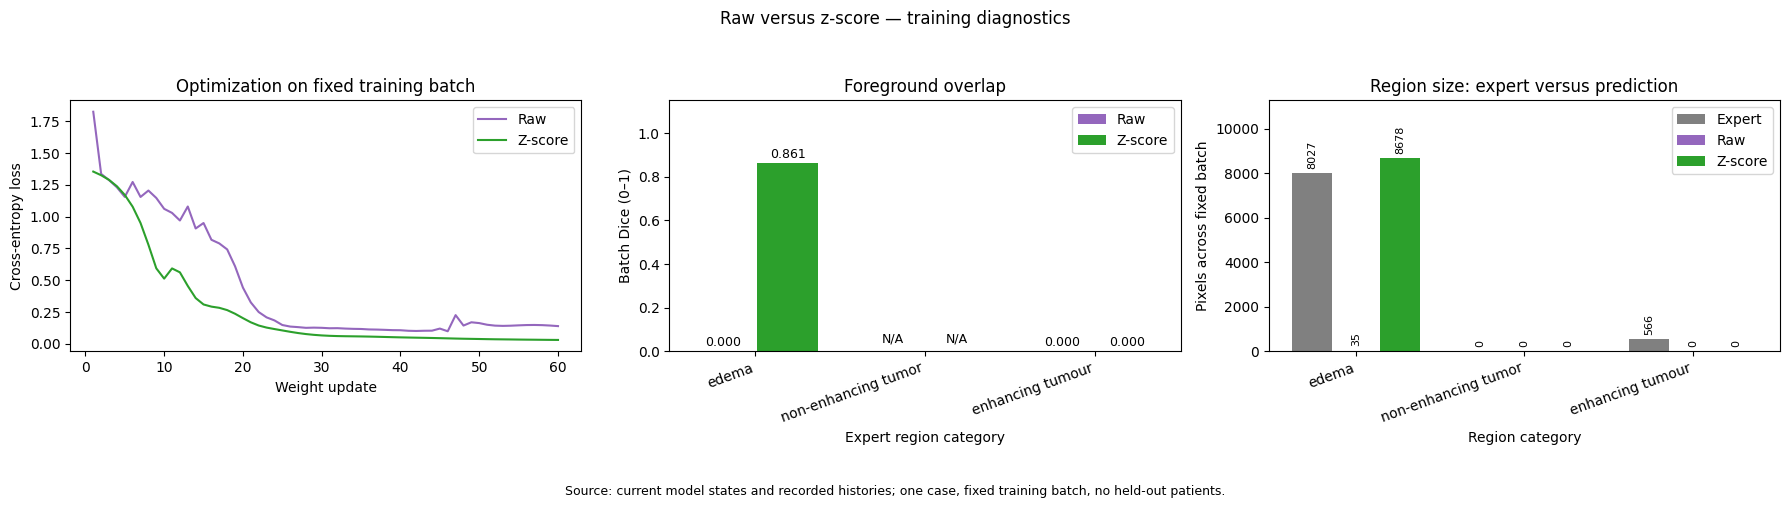

In [55]:
# Loss, Dice, and region-size plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

experiment_colors = {"Raw": "tab:purple", "Z-score": "tab:green"}

# 1. Loss curves: each value was recorded before its weight update.
for name, history in [
    ("Raw", raw_loss_history),
    ("Z-score", zscore_loss_history),
]:
    axes[0].plot(
        np.arange(1, len(history) + 1),
        history,
        label=name,
        color=experiment_colors[name],
    )

axes[0].set(
    title="Optimization on fixed training batch",
    xlabel="Weight update",
    ylabel="Cross-entropy loss",
)
axes[0].legend()

# 2. Foreground Dice.
x = np.arange(len(labels))

for name, offset in [("Raw", -0.19), ("Z-score", 0.19)]:
    values = dice_scores[name]

    axes[1].bar(
        x + offset,
        values,
        width=0.36,
        label=name,
        color=experiment_colors[name],
    )

    for index, value in enumerate(values):
        axes[1].text(
            index + offset,
            0.04 if np.isnan(value) else value + 0.025,
            "N/A" if np.isnan(value) else f"{value:.3f}",
            ha="center",
            fontsize=9,
        )

axes[1].set(
    title="Foreground overlap",
    xlabel="Expert region category",
    ylabel="Batch Dice (0–1)",
    ylim=(0, 1.15),
)
axes[1].set_xticks(x, region_names, rotation=20, ha="right")
axes[1].legend()

# 3. Expert versus predicted region sizes.
for name, counts, offset, color in [
    ("Expert", expert_counts, -0.26, "0.5"),
    ("Raw", prediction_counts["Raw"], 0, experiment_colors["Raw"]),
    ("Z-score", prediction_counts["Z-score"], 0.26, experiment_colors["Z-score"]),
]:
    bars = axes[2].bar(
        x + offset, counts, width=0.24, label=name, color=color
    )
    axes[2].bar_label(bars, rotation=90, padding=3, fontsize=8)

axes[2].set(
    title="Region size: expert versus prediction",
    xlabel="Region category",
    ylabel="Pixels across fixed batch",
)
axes[2].set_xticks(x, region_names, rotation=20, ha="right")
axes[2].margins(y=0.3)
axes[2].legend()

fig.suptitle("Raw versus z-score — training diagnostics")
fig.tight_layout(rect=(0, 0.08, 1, 0.94))
fig.text(
    0.5, 0.01,
    "Source: current model states and recorded histories; "
    "one case, fixed training batch, no held-out patients.",
    ha="center", fontsize=9,
)
plt.show()

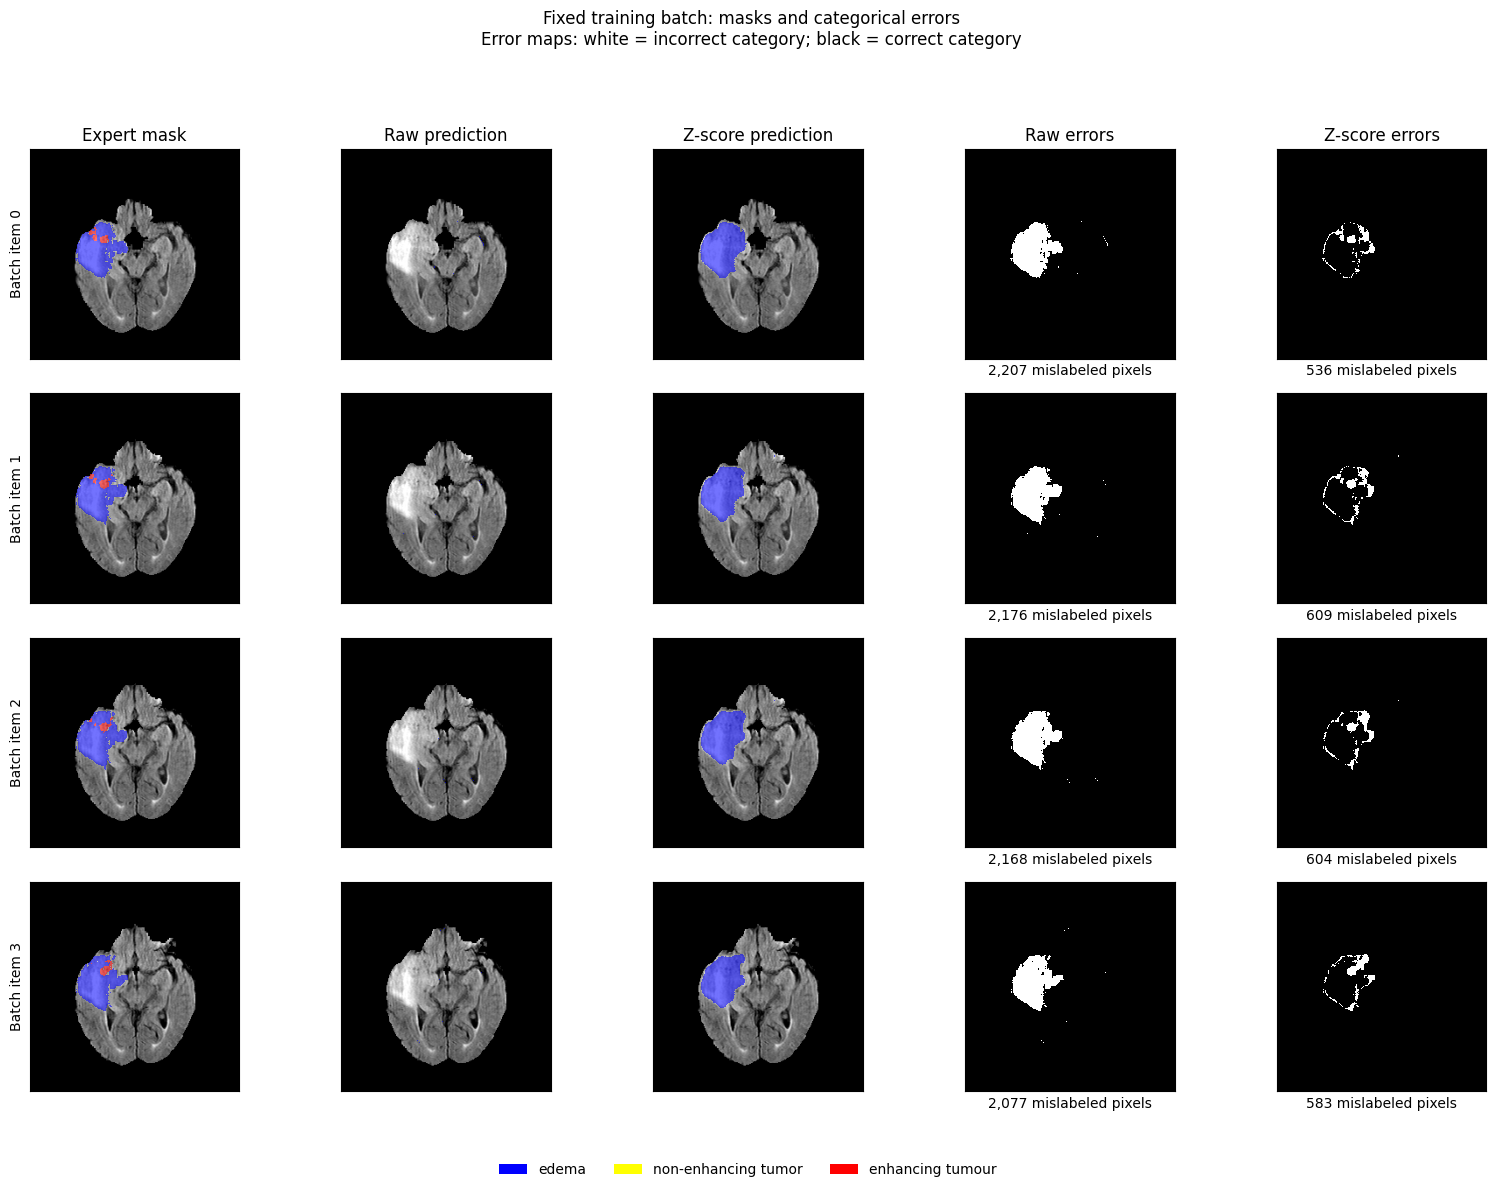

In [56]:
category_colors = ["none", "blue", "yellow", "red"]
category_cmap = ListedColormap(category_colors)
category_cmap.set_bad((0, 0, 0, 0))

category_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5], category_cmap.N
)

display_values = background_images[
    np.isfinite(background_images) & (background_images != 0)
]

low, high = (
    np.percentile(display_values, [1, 99])
    if display_values.size else (0, 1)
)
if high <= low:
    high = low + 1

batch_count = expert.shape[0]
fig, axes = plt.subplots(
    batch_count, 5,
    figsize=(16, 3 * batch_count),
    squeeze=False,
)

column_titles = [
    "Expert mask",
    "Raw prediction",
    "Z-score prediction",
    "Raw errors",
    "Z-score errors",
]

for row in range(batch_count):
    masks_to_show = [
        expert[row],
        predictions["Raw"][row],
        predictions["Z-score"][row],
    ]

    for col, region_mask in enumerate(masks_to_show):
        axes[row, col].imshow(
            background_images[row],
            cmap="gray",
            vmin=low,
            vmax=high,
            origin="upper",
        )

        overlay = np.ma.masked_where(region_mask == 0, region_mask)

        axes[row, col].imshow(
            overlay,
            cmap=category_cmap,
            norm=category_norm,
            alpha=0.55,
            interpolation="nearest",
            origin="upper",
        )

    for col, name in [(3, "Raw"), (4, "Z-score")]:
        errors = predictions[name][row] != expert[row]

        axes[row, col].imshow(
            errors,
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest",
            origin="upper",
        )
        axes[row, col].set_xlabel(
            f"{int(errors.sum()):,} mislabeled pixels"
        )

    axes[row, 0].set_ylabel(f"Batch item {row}")

    for col in range(5):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        if row == 0:
            axes[row, col].set_title(column_titles[col])

legend = [
    Patch(
        facecolor=category_colors[label],
        label=metadata["labels"][str(label)],
    )
    for label in labels
]

fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle(
    "Fixed training batch: masks and categorical errors\n"
    "Error maps: white = incorrect category; black = correct category"
)
fig.tight_layout(rect=(0, 0.05, 1, 0.94))
plt.show()

### Raw versus z-score: fixed-batch findings

After 60 updates, z-score normalization achieved edema Dice
0.861, compared with 0.000 for raw input. Spatial error maps
showed fewer mislabeled pixels on all four training slices.

The normalized model still overpredicted edema overall and
failed to predict the enhancing-tumor category. Non-enhancing
tumor was absent and could not be evaluated.

Normalization helped this training exercise, but low overall
loss did not establish successful segmentation of every class.
Generalization remains untested.

### Conclusion:
We adopt z-score normalization as a provisional preprocessing default because it improved edema segmentation in our fixed-batch experiment, while performance on other regions and unseen patients remains unverified.